In [1]:
import sys
print(sys.executable)

C:\Users\Admin\Desktop\parcours-ia\.venv\Scripts\python.exe


In [2]:
import pandas as pd
pd.__version__

'3.1.0'

In [3]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator

# Charte commune des figures du dépôt (style/charte.py) : polices, couleurs, export clair et sombre
sys.path.insert(0, "../../style")
from charte import charger_charte, en_francais, pourcentage, sauver_clair_et_sombre
charger_charte()
Path("resultats").mkdir(exist_ok=True)

In [4]:
commandes = pd.read_csv("donnees/DataCoSupplyChainDataset.csv", encoding = "latin-1")
commandes.shape

(180519, 53)

In [5]:
colonnes_identite_client = ["Customer Fname", "Customer Lname", "Customer Street",
                            "Customer Email", "Customer Password"]
commandes = commandes.drop(columns=colonnes_identite_client)
commandes.shape

(180519, 48)

In [6]:
commandes.head(3).T

,0,1,2
Type,DEBIT,TRANSFER,CASH
Days for shipping (real),3,5,4
Days for shipment (scheduled),4,4,4
Benefit per order,91.25,-249.089996,-247.779999
Sales per customer,314.640015,311.359985,309.720001
Delivery Status,Advance shipping,Late delivery,Shipping on time
Late_delivery_risk,0,1,0
Category Id,73,73,73
Category Name,Sporting Goods,Sporting Goods,Sporting Goods
Customer City,Caguas,Caguas,San Jose


In [7]:
commandes["Late_delivery_risk"].mean()

np.float64(0.5482913155955883)

In [8]:
retard_par_mode = commandes.groupby("Shipping Mode")["Late_delivery_risk"].mean().sort_values()
retard_par_mode

Shipping Mode
Standard Class    0.380717
Same Day          0.457430
Second Class      0.766328
First Class       0.953225
Name: Late_delivery_risk, dtype: float64

In [9]:
commandes["date_commande"] = pd.to_datetime(commandes["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
commandes["date_commande"].min(), commandes["date_commande"].max()


(Timestamp('2015-01-01 00:00:00'), Timestamp('2018-01-31 23:38:00'))

In [10]:
est_entrainement = commandes["date_commande"] < "2017-01-01"
est_validation = (commandes["date_commande"] >= "2017-01-01") & (commandes["date_commande"] < "2017-07-01")
est_test_scelle = commandes["date_commande"] >= "2017-07-01"

est_entrainement.sum(), est_validation.sum(), est_test_scelle.sum()


(np.int64(125200), np.int64(30950), np.int64(24369))

In [11]:
from sklearn.metrics import accuracy_score

vraies_valeurs = commandes.loc[est_validation, "Late_delivery_risk"]

prediction_toujours_en_retard = [1] * len(vraies_valeurs)
accuracy_score(vraies_valeurs, prediction_toujours_en_retard)


0.5405169628432956

In [12]:
prediction_regle_du_mode = commandes.loc[est_validation, "Shipping Mode"].isin(["First Class", "Second Class"]).astype(int)
accuracy_score(vraies_valeurs, prediction_regle_du_mode)

0.6873667205169628

In [13]:
commandes.nunique().sort_values()

Product Description                   0
Product Status                        1
Late_delivery_risk                    2
Customer Country                      2
Customer Segment                      3
Days for shipment (scheduled)         4
Delivery Status                       4
Type                                  4
Shipping Mode                         4
Order Item Quantity                   5
Market                                5
Days for shipping (real)              7
Order Status                          9
Department Name                      11
Department Id                        11
Order Item Discount Rate             18
Order Region                         23
Customer State                       46
Category Name                        50
Product Category Id                  51
Category Id                          51
Product Price                        75
Order Item Product Price             75
Order Item Cardprod Id              118
Product Card Id                     118


In [14]:
commandes["mois_commande"] = commandes["date_commande"].dt.month
commandes["jour_semaine_commande"] = commandes["date_commande"].dt.day_of_week
commandes["heure_commande"] = commandes["date_commande"].dt.hour

colonnes_a_exclure = [
    "Product Description", "Product Status", "Product Image",
    "Order Id", "Order Item Id", "Customer Id", "Order Customer Id", "Order Item Cardprod Id",
    "Product Card Id", "Product Category Id", "Category Id", "Department Id",
    "order date (DateOrders)", "shipping date (DateOrders)", "date_commande",
]
colonnes_candidates = [c for c in commandes.columns if c not in colonnes_a_exclure + ["Late_delivery_risk"]]
len(colonnes_candidates)


36

In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

variables = commandes[colonnes_candidates].copy()
for colonne in variables.columns:
    if not pd.api.types.is_numeric_dtype(variables[colonne]):
        variables[colonne] = variables[colonne].astype("category")
        if variables[colonne].nunique() > 255:
            variables[colonne] = variables[colonne].cat.codes

modele = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0)
modele.fit(variables[est_entrainement], commandes.loc[est_entrainement, "Late_delivery_risk"])

probabilites = modele.predict_proba(variables[est_validation])[:, 1]
accuracy_score(vraies_valeurs, probabilites > 0.5), roc_auc_score(vraies_valeurs, probabilites)


(1.0, 1.0)

In [16]:
for numero, colonne in enumerate(colonnes_candidates, start=1):
    print(numero, colonne)

1 Type
2 Days for shipping (real)
3 Days for shipment (scheduled)
4 Benefit per order
5 Sales per customer
6 Delivery Status
7 Category Name
8 Customer City
9 Customer Country
10 Customer Segment
11 Customer State
12 Customer Zipcode
13 Department Name
14 Latitude
15 Longitude
16 Market
17 Order City
18 Order Country
19 Order Item Discount
20 Order Item Discount Rate
21 Order Item Product Price
22 Order Item Profit Ratio
23 Order Item Quantity
24 Sales
25 Order Item Total
26 Order Profit Per Order
27 Order Region
28 Order State
29 Order Status
30 Order Zipcode
31 Product Name
32 Product Price
33 Shipping Mode
34 mois_commande
35 jour_semaine_commande
36 heure_commande


In [17]:
colonnes_qui_fuient = ["Delivery Status", "Days for shipping (real)", "Order Status"]
colonnes_sans_fuite = [c for c in colonnes_candidates if c not in colonnes_qui_fuient]

variables_sans_fuite = variables[colonnes_sans_fuite]
modele_sans_fuite = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0)
modele_sans_fuite.fit(variables_sans_fuite[est_entrainement], commandes.loc[est_entrainement, "Late_delivery_risk"])

probabilites_sans_fuite = modele_sans_fuite.predict_proba(variables_sans_fuite[est_validation])[:, 1]
accuracy_score(vraies_valeurs, probabilites_sans_fuite > 0.5), roc_auc_score(vraies_valeurs, probabilites_sans_fuite)

(0.7054281098546042, 0.7546946160337905)

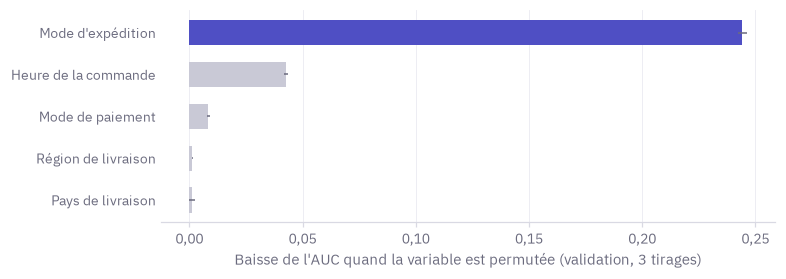

In [18]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    modele_sans_fuite, variables_sans_fuite[est_validation], vraies_valeurs,
    scoring="roc_auc", n_repeats=3, random_state=0)
importance_par_colonne = pd.Series(importance.importances_mean, index=colonnes_sans_fuite).sort_values()

NOMS_LISIBLES = {"Shipping Mode": "Mode d'expédition", "heure_commande": "Heure de la commande", "Type": "Mode de paiement",
                 "Order Region": "Région de livraison", "Order Country": "Pays de livraison", "Latitude": "Latitude du magasin",
                 "Longitude": "Longitude du magasin", "Product Name": "Produit", "jour_semaine_commande": "Jour de la semaine",
                 "mois_commande": "Mois de la commande", "Order City": "Ville de livraison"}


def tracer_importance(couleurs):
    premieres = importance_par_colonne.tail(5)
    ecarts = pd.Series(importance.importances_std, index=colonnes_sans_fuite)[premieres.index]
    teintes = [couleurs["neutre"]] * (len(premieres) - 1) + [couleurs["accent"]]
    figure, axe = plt.subplots(figsize=(7.2, 2.5))
    axe.barh([NOMS_LISIBLES.get(nom, nom) for nom in premieres.index], premieres.values, xerr=ecarts.values,
             color=teintes, height=0.6, error_kw={"ecolor": couleurs["trait"], "elinewidth": 1, "capsize": 0})
    axe.xaxis.set_major_formatter(en_francais(2))
    axe.set_xlabel("Baisse de l'AUC quand la variable est permutée (validation, 3 tirages)")
    axe.grid(axis="y", visible=False)
    axe.spines["left"].set_visible(False)
    axe.tick_params(axis="y", length=0)
    return figure


sauver_clair_et_sombre(tracer_importance, "resultats/importance_variables")

In [19]:
modele_courbe = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0,
                                               max_iter=300, early_stopping=False)
modele_courbe.fit(variables_sans_fuite[est_entrainement], commandes.loc[est_entrainement, "Late_delivery_risk"])

vraies_entrainement = commandes.loc[est_entrainement, "Late_delivery_risk"]
auc_entrainement = [roc_auc_score(vraies_entrainement, p[:, 1])
                    for p in modele_courbe.staged_predict_proba(variables_sans_fuite[est_entrainement])]
auc_validation = [roc_auc_score(vraies_valeurs, p[:, 1])
                  for p in modele_courbe.staged_predict_proba(variables_sans_fuite[est_validation])]


def tracer_courbe(couleurs):
    arbres = np.arange(1, len(auc_validation) + 1)
    figure, axe = plt.subplots(figsize=(7.2, 3.0))
    axe.plot(arbres, auc_entrainement, color=couleurs["trait"], linestyle=(0, (4, 2)), linewidth=1.6)
    axe.plot(arbres, auc_validation, color=couleurs["accent"])
    axe.text(arbres[-1] + 5, auc_entrainement[-1], "entraînement", va="center", color=couleurs["secondaire"])
    axe.text(arbres[-1] + 5, auc_validation[-1] + 0.004, "validation", va="bottom", color=couleurs["accent"])  # au-dessus de la grille
    meilleur = int(np.argmax(auc_validation))
    rang = arbres[meilleur]
    axe.plot(rang, auc_validation[meilleur], "o", color=couleurs["accent"], markersize=5)
    etiquette = f"maximum {auc_validation[meilleur]:.3f}".replace(".", ",") + f" au {rang}{'er' if rang == 1 else 'e'} arbre"
    axe.annotate(etiquette, (rang, auc_validation[meilleur]), xytext=(10, 9), textcoords="offset points",
                 fontsize=8.5, color=couleurs["secondaire"])
    axe.set_xlim(0, 360)
    axe.set_xticks([1, 50, 100, 150, 200, 250, 300])
    axe.yaxis.set_major_locator(MultipleLocator(0.05))
    axe.yaxis.set_major_formatter(en_francais(2))
    axe.set_xlabel("Nombre d'arbres")
    axe.set_ylabel("AUC")
    axe.grid(axis="x", visible=False)
    return figure


sauver_clair_et_sombre(tracer_courbe, "resultats/courbe_apprentissage")

In [20]:
# Test scellé : on entraîne sur entraînement + validation, on note UNE fois sur le test
vraies_test = commandes.loc[est_test_scelle, "Late_delivery_risk"]
modele_final = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0)
modele_final.fit(variables_sans_fuite[est_entrainement | est_validation],
                 commandes.loc[est_entrainement | est_validation, "Late_delivery_risk"])
probabilites_test = modele_final.predict_proba(variables_sans_fuite[est_test_scelle])[:, 1]
exactitude_test = accuracy_score(vraies_test, probabilites_test > 0.5)
auc_test = roc_auc_score(vraies_test, probabilites_test)
exactitude_test, auc_test

(0.7219007755755262, 0.7736820248100259)

In [21]:
scores = pd.DataFrame([
    {"modele": "Toujours en retard", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, prediction_toujours_en_retard), "auc": None},
    {"modele": "Règle du mode d'expédition", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, prediction_regle_du_mode), "auc": None},
    {"modele": "Boosting, avec fuite", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, probabilites > 0.5), "auc": roc_auc_score(vraies_valeurs, probabilites)},
    {"modele": "Boosting, sans fuite", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, probabilites_sans_fuite > 0.5), "auc": roc_auc_score(vraies_valeurs, probabilites_sans_fuite)},
    {"modele": "Boosting, sans fuite", "morceau": "test", "exactitude": exactitude_test, "auc": auc_test},
])
scores.to_csv("resultats/scores.csv", index=False)
scores.round(3)

,modele,morceau,exactitude,auc
0,Toujours en retard,validation,0.541,NaN
1,Règle du mode d'expédition,validation,0.687,NaN
2,"Boosting, avec fuite",validation,1.000,1.000
3,"Boosting, sans fuite",validation,0.705,0.755
4,"Boosting, sans fuite",test,0.722,0.774


In [22]:
def tracer_scores(couleurs):
    exactitudes = scores[scores["morceau"] == "validation"].set_index("modele")["exactitude"]
    modeles = ["Toujours en retard", "Règle du mode d'expédition", "Boosting, sans fuite", "Boosting, avec fuite"]
    etiquettes = ["Toujours « en retard »", "Règle : mode d'expédition", "Boosting, sans fuite", "Boosting, avec fuite"]
    teintes = [couleurs["neutre"], couleurs["neutre"], couleurs["accent"], "none"]
    figure, axe = plt.subplots(figsize=(7.2, 2.6))
    # barh trace de bas en haut : on inverse les listes pour lire de haut en bas
    barres = axe.barh(etiquettes[::-1], [100 * exactitudes[m] for m in modeles[::-1]], color=teintes[::-1], height=0.6)
    barre_fuite = barres[0]
    barre_fuite.set_edgecolor(couleurs["trait"])
    barre_fuite.set_linestyle((0, (3, 2)))
    barre_fuite.set_linewidth(1.1)
    for barre, modele_nom in zip(barres, modeles[::-1]):
        axe.text(barre.get_width() + 1.5, barre.get_y() + barre.get_height() / 2, pourcentage(exactitudes[modele_nom]),
                 va="center", color=couleurs["texte"])
    axe.text(50, barre_fuite.get_y() + barre_fuite.get_height() / 2, "colonnes connues seulement après la livraison",
             ha="center", va="center", fontsize=8.5, color=couleurs["secondaire"])
    axe.set_xlim(0, 114)
    axe.set_xticks([0, 25, 50, 75, 100])
    axe.set_xlabel("Exactitude (%) sur la validation, 1er semestre 2017")
    axe.grid(axis="y", visible=False)
    axe.spines["left"].set_visible(False)
    axe.tick_params(axis="y", length=0)
    return figure


sauver_clair_et_sombre(tracer_scores, "resultats/scores_validation")